# Multi-agent coordination concepts using a StateGraph


### Patterns covered

* ### Pipeline (peer-to-peer, deterministic flow)
    * deterministic sequence with clear start → l1 → l2 → l3 → END and printed handoffs.
* ### Network (peer-to-peer, stochastic routing)
    * stochastic routing where agents pick next hops randomly, producing non-linear traces and possible cycles.
* ### Supervisor (orchestrator supervising agents)
    * a single orchestrator decides which worker to call; workers return control to the supervisor.
* ### Hierarchical (nested control with upward handoff)
    * agents route between nested subordinates and parents, creating local loops and higher-level control.

In [ ]:
!pip install pyppeteer
from typing import Literal
import random
from IPython.display import Image, display
import nest_asyncio
from langchain_core.runnables.graph import MermaidDrawMethod
from langgraph.graph import START, END, StateGraph
from langgraph.graph.message import MessagesState
from langgraph.types import Command


# Langgraph MessageState is built in schema for chat and conversations
# It handles conversation history.
# It appends incoming and outgoing message to a list



# Command in Langraph 
# When a node returns a Command, you can specify:
# update: A dictionary containing the state updates to apply.
# goto: The name of the target node (or list of nodes) to jump to next.
# resume: Used alongside interrupt() to send user feedback back into a paused graph.



In [3]:
nest_asyncio.apply()

# 1.  Peer to Peer (Deterministic)

In [4]:
# Pipeline

def l1_agent(state: MessagesState):
    print(f"Started with l1_agent")
    next_node = "l2_agent"
    print(f"Handed off to {next_node}")



def l2_agent(state: MessagesState):
    next_node = "l3_agent"
    print(f"Handed off to {next_node}")



def l3_agent(state: MessagesState):
    next_node = END
    print(f"Handed off to {next_node}")
    

In [5]:
workflow = StateGraph(MessagesState)
workflow.add_node(l1_agent)
workflow.add_node(l2_agent)
workflow.add_node(l3_agent)

workflow.add_edge(START, "l1_agent")
workflow.add_edge("l1_agent", "l2_agent")
workflow.add_edge("l2_agent", "l3_agent")
workflow.add_edge("l3_agent", END)

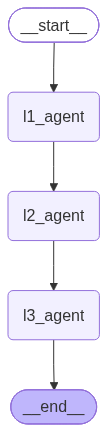

In [6]:
graph = workflow.compile()

display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)



In [7]:
graph.invoke(input={})

Started with l1_agent
Handed off to l2_agent
Handed off to l3_agent
Handed off to __end__


# 2. Peer to Peer (Network)

In [8]:
def l1_agent(state : MessagesState) -> Command[Literal["l2_agent","l3_agent",END]]:
    print(f"Started with l1_agent")
    next_node = random.choice(["l2_agent","l3_agent",END])
    print(f"(handoff to {next_node})")

    return Command(goto= next_node)

In [9]:
def l2_agent(state : MessagesState) -> Command[Literal["l1_agent","l3_agent",END]]:
    next_node = random.choice(["l2_agent","l3_agent",END])
    print(f"(handoff to {next_node})")

    return Command(goto= next_node)

In [10]:
def l3_agent(state : MessagesState) -> Command[Literal["l1_agent","l2_agent",END]]:
    print(f"Started with l1_agent")
    next_node = random.choice(["l1_agent","l2_agent",END])
    print(f"(handoff to {next_node})")

    return Command(goto= next_node)

In [11]:
workflow = StateGraph(MessagesState)
workflow.add_node(l1_agent)
workflow.add_node(l2_agent)
workflow.add_node(l3_agent)

workflow.add_edge(START, "l1_agent")


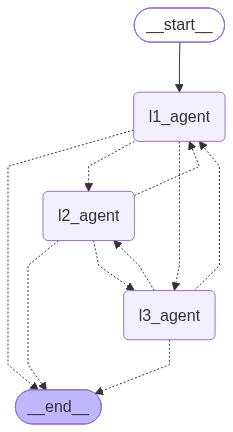

In [12]:
graph = workflow.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
graph.invoke(input = {})

Started with l1_agent
(handoff to l2_agent)
(handoff to l3_agent)
Started with l1_agent
(handoff to __end__)


In [14]:
graph.invoke(input = {})

Started with l1_agent
(handoff to __end__)


# 3. Orchestrator (Supervisor)

In [15]:
def supervisor(state: MessagesState) -> Command[Literal["l1_agent", "l2_agent", END]]:
    next_node = random.choice(["l1_agent", "l2_agent", END])
    print(f"supervisor handed off to {next_node}")
    return Command(
        goto=next_node
    )

In [16]:
def l1_agent(state: MessagesState) -> Command[Literal["supervisor"]]:
    next_node = "supervisor"
    print(f"l1_agent handed off to {next_node}")
    return Command(
        goto=next_node
    )

In [17]:
def l2_agent(state: MessagesState) -> Command[Literal["supervisor"]]:
    next_node = "supervisor"
    print(f"l2_agent handed off to {next_node}")
    return Command(
        goto=next_node
    )

In [18]:
workflow = StateGraph(MessagesState)
workflow.add_node(supervisor)
workflow.add_node(l1_agent)
workflow.add_node(l2_agent)

workflow.add_edge(START, "supervisor")

[INFO] Starting Chromium download.
100%|██████████| 141M/141M [00:10<00:00, 13.5Mb/s] 
[INFO] Beginning extraction
[INFO] Chromium extracted to: /Users/oasis/Library/Application Support/pyppeteer/local-chromium/1181205


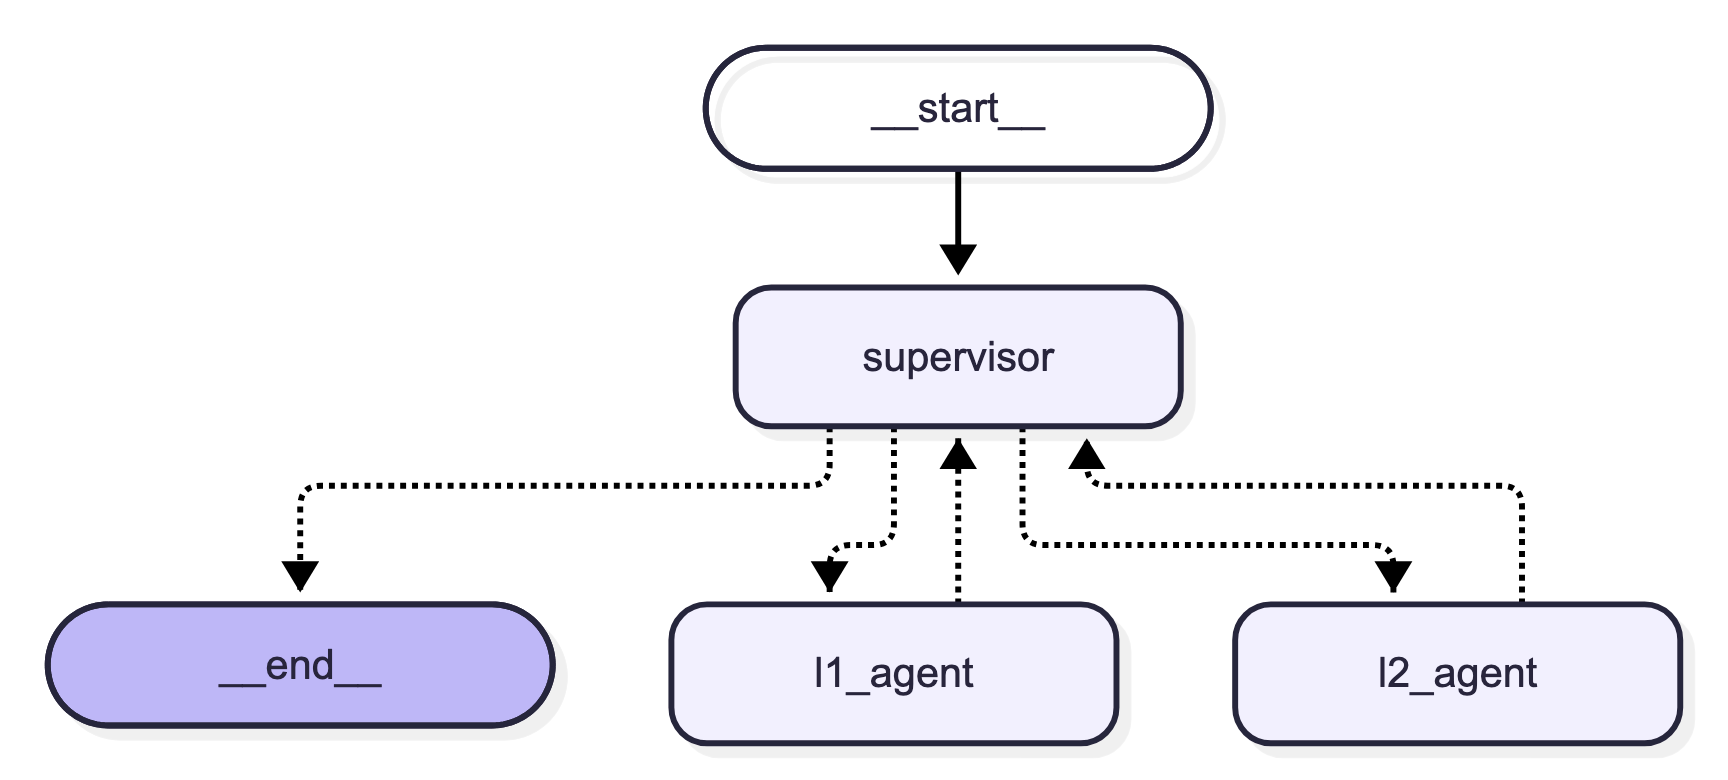

In [19]:
graph = workflow.compile()

display(
    Image(
        graph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.PYPPETEER
        )
    )
)

In [22]:
graph.invoke(input={})

supervisor handed off to l2_agent
l2_agent handed off to supervisor
supervisor handed off to l2_agent
l2_agent handed off to supervisor
supervisor handed off to l2_agent
l2_agent handed off to supervisor
supervisor handed off to __end__


# 4. Hierarchical

In [23]:
def l1_agent(state: MessagesState) -> Command[Literal["l2_agent", "l3_agent", END]]:
    next_node = random.choice(["l2_agent", "l3_agent", END])
    print(f"l1_agent handed off to {next_node}")
    return Command(
        goto=next_node
    )

In [24]:
def l2_agent(state: MessagesState) -> Command[Literal["l4_agent", "l5_agent", "l1_agent"]]:
    next_node = random.choice(["l1_agent", "l4_agent", "l5_agent"])
    print(f"l2_agent handed off to {next_node}")
    return Command(
        goto=next_node
    )

In [25]:
def l3_agent(state: MessagesState) -> Command[Literal["l1_agent"]]:
    next_node = "l1_agent"
    print(f"l3_agent handed off to {next_node}")
    return Command(
        goto=next_node
    )

In [26]:
def l4_agent(state: MessagesState) -> Command[Literal["l2_agent"]]:
    next_node = "l2_agent"
    print(f"l4_agent handed off to {next_node}")
    return Command(
        goto=next_node
    )

In [27]:
def l5_agent(state: MessagesState) -> Command[Literal["l2_agent"]]:
    next_node = "l2_agent"
    print(f"l5_agent handed off to {next_node}")
    return Command(
        goto=next_node
    )

In [28]:
workflow = StateGraph(MessagesState)
workflow.add_node(l1_agent)
workflow.add_node(l2_agent)
workflow.add_node(l3_agent)
workflow.add_node(l4_agent)
workflow.add_node(l5_agent)

workflow.add_edge(START, "l1_agent")

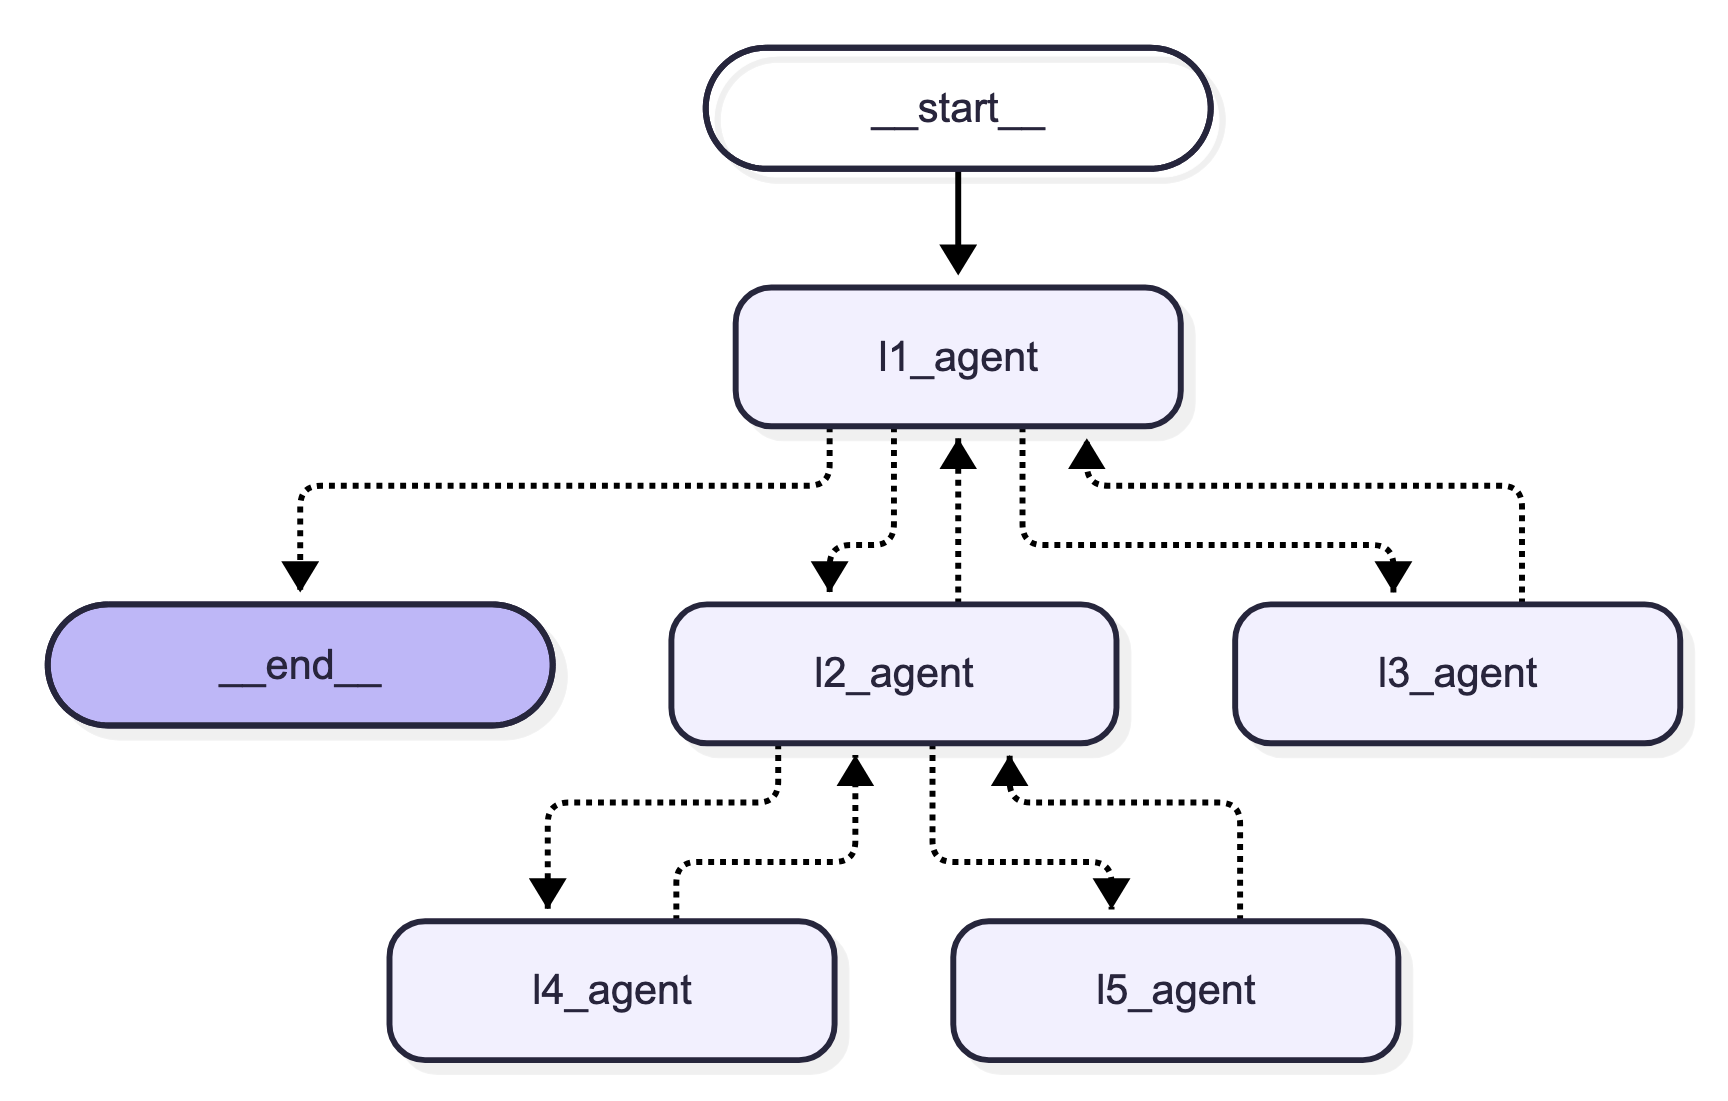

In [29]:
graph = workflow.compile()

display(
    Image(
        graph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.PYPPETEER
        )
    )
)

In [36]:
graph.invoke(
    input={}
)

l1_agent handed off to l3_agent
l3_agent handed off to l1_agent
l1_agent handed off to l2_agent
l2_agent handed off to l5_agent
l5_agent handed off to l2_agent
l2_agent handed off to l4_agent
l4_agent handed off to l2_agent
l2_agent handed off to l4_agent
l4_agent handed off to l2_agent
l2_agent handed off to l1_agent
l1_agent handed off to __end__


We can improve by :
* replacing random.choice with probability-weighted selections to model preference.
* introducing message payloads in MessagesState and having agents read/write fields.
* implementing logging, timeouts, or max-step limits to prevent infinite cycles in networks.
* extending the supervisor with simple policies (round-robin, load-based) before returning next_node.
* exporting graph structure to Mermaid for documentation or to generate sequence diagrams.
